**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 7**
Análisis de Componentes Principales (PCA)

---

* Equipo 67
*   NOMBRE: Adolfo Siliceo Vásquez, Héctor André Simental Gaxiola, Carlos Armando Solis Contreras, José Carlos Sierra Pérez
*   MATRÍCULA: A01841467, A01840739, A01841611, A01055689

En esta actividad trabajarás con el archivo `automobile_dataset.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de automóviles, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar diferentes aspectos de los vehículos y sus precios, e incluyen información sobre el fabricante, tipo de motor, dimensiones, peso, rendimiento de combustible y otras especificaciones técnicas. Los indicadores incluidos son:

* `symboling`: Nivel de riesgo del seguro del automóvil, de -3 (bajo riesgo) a +3 (alto riesgo)
* `normalized_losses`: Pérdidas normalizadas del seguro (valor numérico de la aseguradora, algunas veces faltante)
* `make`: Marca del automóvil (por ejemplo, Audi, BMW, Honda)
* `fuel_type`: Tipo de combustible (gasolina o diésel)
* `aspiration`: Tipo de aspiración del motor (normal o turbo)
* `num_doors`: Número de puertas del automóvil (dos o cuatro)
* `body_style`: Estilo de carrocería (sedán, hatchback, wagon, hardtop, convertible)
* `drive_wheels`: Tipo de tracción (fwd: delantera, rwd: trasera, 4wd: en las cuatro ruedas)
* `engine_location`: Ubicación del motor (delantero o trasero)
* `wheel_base`: Distancia entre ejes (en pulgadas)
* `length`: Largo total del automóvil (en pulgadas)
* `width`: Ancho total del automóvil (en pulgadas)
* `height`: Altura total del automóvil (en pulgadas)
* `curb_weight`: Peso del automóvil sin carga (en libras)
* `engine_type`: Tipo de motor (OHV, OHC, DOHC, etc.)
* `num_cylinders`: Número de cilindros del motor
* `engine_size`: Tamaño del motor (en cc)
* `fuel_system`: Sistema de combustible (por ejemplo, mpfi, 2bbl, 4bbl)
* `bore`: Diámetro del cilindro (en pulgadas)
* `stroke`: Carrera del pistón (en pulgadas)
* `compression_ratio`: Relación de compresión del motor
* `horsepower`: Potencia del motor (en caballos de fuerza)
* `peak_rpm`: Revoluciones máximas por minuto
* `city_mpg`: Rendimiento de combustible en ciudad (millas por galón)
* `highway_mpg`: Rendimiento de combustible en carretera (millas por galón)
* `price`: Precio del automóvil (en dólares estadounidenses) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [ ]:
%pip install seaborn

In [ ]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA



1. Descarga el archivo: `automobile_dataset.csv` y guarda, en un dataframe (`cars_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Al revisar los primeros registros, notarás que la columna `normalized_losses` contiene el símbolo `?`. Esto sugiere que se utilizó para indicar valores faltantes. Identifica todas las columnas que presentan este símbolo.
* Sustituye el símbolo `?` por valores faltantes (`NaN`) y convierte las columnas al tipo de dato adecuado. Esto es necesario porque la presencia del símbolo pudo haber hecho que pandas las interpretara como object, aunque en realidad no lo fueran.

In [ ]:
cars_df = pd.read_csv('automobile_dataset.csv')

cars_df.info()

print("\n")
print('Columnas con valores "?":')
for columna in cars_df.columns:
    cantidad = cars_df[columna].astype(str).str.strip().eq('?').sum()
    if cantidad > 0:
        print(f'{columna}: {cantidad}')

cars_df.replace('?', np.nan, inplace=True)

columnas_numericas = [
    'normalized_losses', 'bore', 'stroke',
    'horsepower', 'peak_rpm'
]

for columna in columnas_numericas:
    cars_df[columna] = pd.to_numeric(
        cars_df[columna], errors='coerce'
    )

print("\n")
cars_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

--------------
Cinco columnas problemáticas se han convertido a flotante. Los valores faltantes están representados por NaN, para realizar analisis estadistico y grafico.
--------------

# Análisis exploratorio de datos (univariado)

2. Antes de iniciar con el análisis univariado, verifica si hay registros duplicados e imprime el porcentaje de faltantes por columna.
* Obtén las estadísticas descriptivas, separado las numéricas (incluye asimetría y curtosis) y las categóricas (incluye tablas de frecuencias).
* Genera histogramas para las numéricas y diagramas de barras para las categóricas.

Duplicados: 0


,Faltantes,Porcentaje (%)
symboling,0,0.00
normalized_losses,41,20.00
make,0,0.00
fuel_type,0,0.00
aspiration,0,0.00
num_doors,0,0.00
body_style,0,0.00
drive_wheels,0,0.00
engine_location,0,0.00
wheel_base,0,0.00


,count,mean,std,min,25%,50%,75%,max,Asimetria,Curtosis
symboling,205.0,0.83,1.25,-2.00,0.00,1.00,2.00,3.00,0.21,-0.68
normalized_losses,164.0,122.00,35.44,65.00,94.00,115.00,150.00,256.00,0.77,0.53
wheel_base,205.0,98.76,6.02,86.60,94.50,97.00,102.40,120.90,1.05,1.02
length,205.0,174.05,12.34,141.10,166.30,173.20,183.10,208.10,0.16,-0.08
width,205.0,65.91,2.15,60.30,64.10,65.50,66.90,72.30,0.90,0.70
height,205.0,53.72,2.44,47.80,52.00,54.10,55.50,59.80,0.06,-0.44
curb_weight,205.0,2555.57,520.68,1488.00,2145.00,2414.00,2935.00,4066.00,0.68,-0.04
num_cylinders,205.0,4.38,1.08,2.00,4.00,4.00,4.00,12.00,2.82,13.71
engine_size,205.0,126.91,41.64,61.00,97.00,120.00,141.00,326.00,1.95,5.31
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.59,3.94,0.02,-0.83



 make


,Frecuencia,Porcentaje (%)
make,,
toyota,32,15.61
nissan,18,8.78
mazda,17,8.29
mitsubishi,13,6.34
honda,13,6.34
subaru,12,5.85
volkswagen,12,5.85
volvo,11,5.37
peugot,11,5.37


...

,Frecuencia,Porcentaje (%)
engine_location,,
front,202,98.54
rear,3,1.46



 engine_type


,Frecuencia,Porcentaje (%)
engine_type,,
ohc,148,72.20
ohcf,15,7.32
ohcv,13,6.34
dohc,12,5.85
l,12,5.85
rotor,4,1.95
dohcv,1,0.49



 fuel_system


,Frecuencia,Porcentaje (%)
fuel_system,,
mpfi,94,45.85
2bbl,66,32.20
idi,20,9.76
1bbl,11,5.37
spdi,9,4.39
4bbl,3,1.46
mfi,1,0.49
spfi,1,0.49


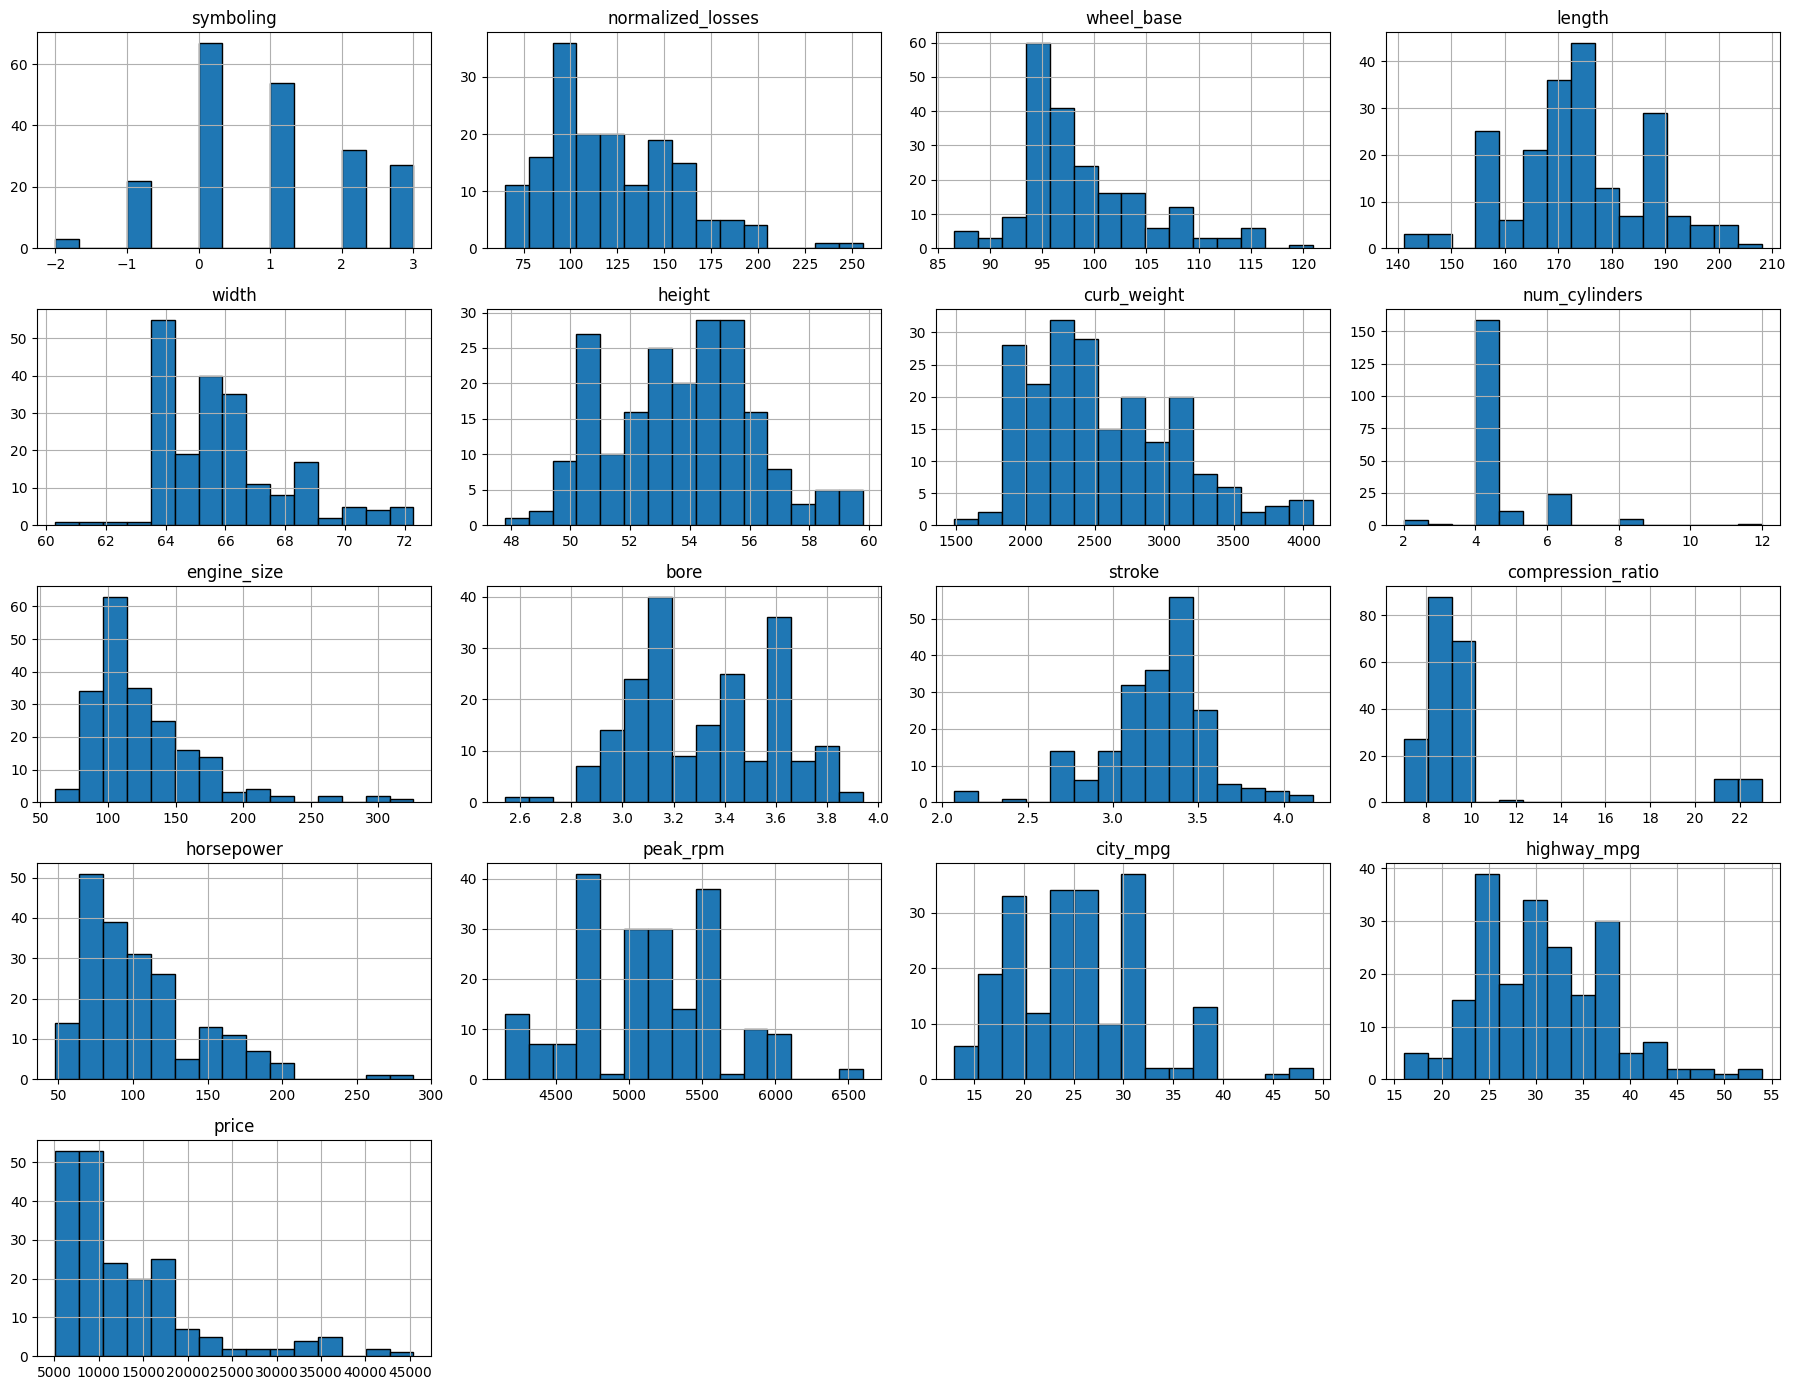

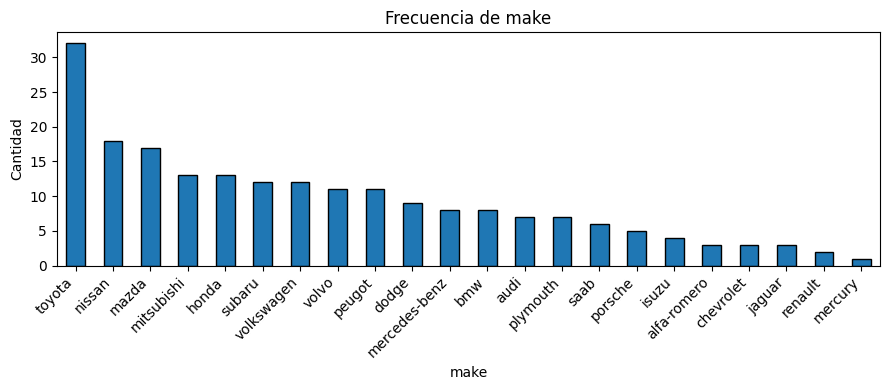

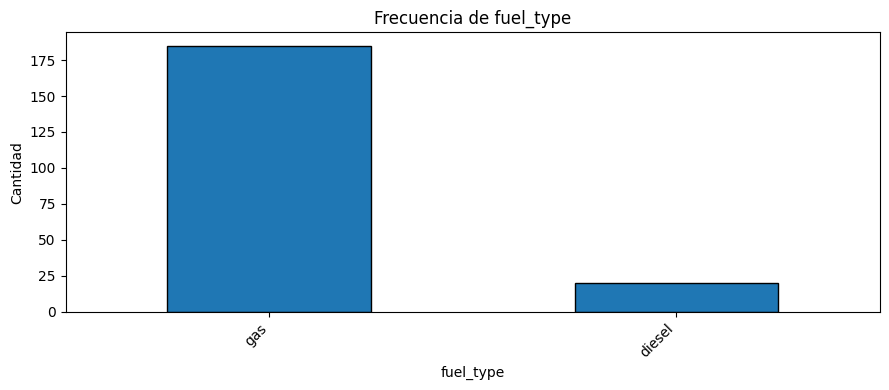

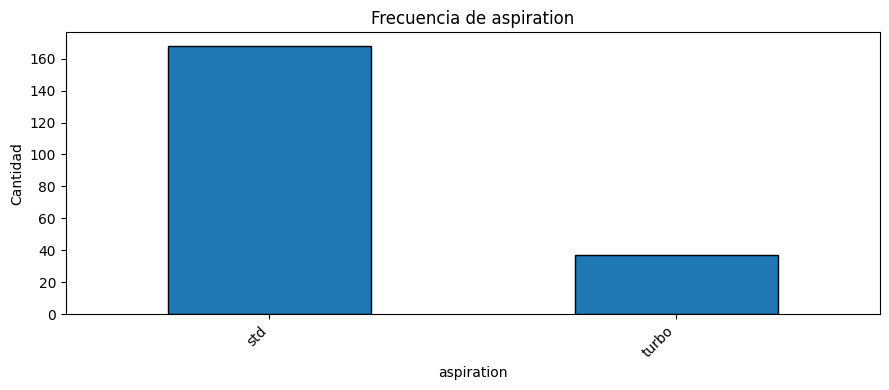

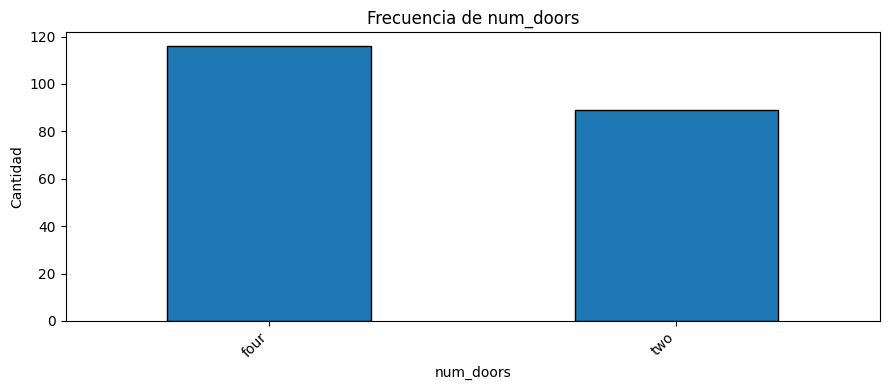

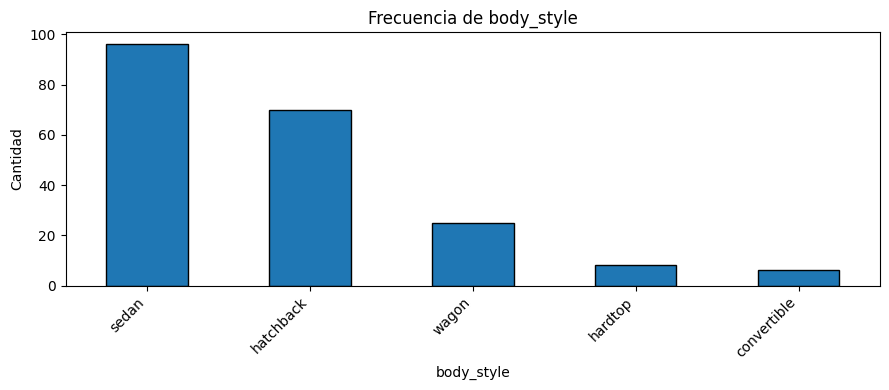

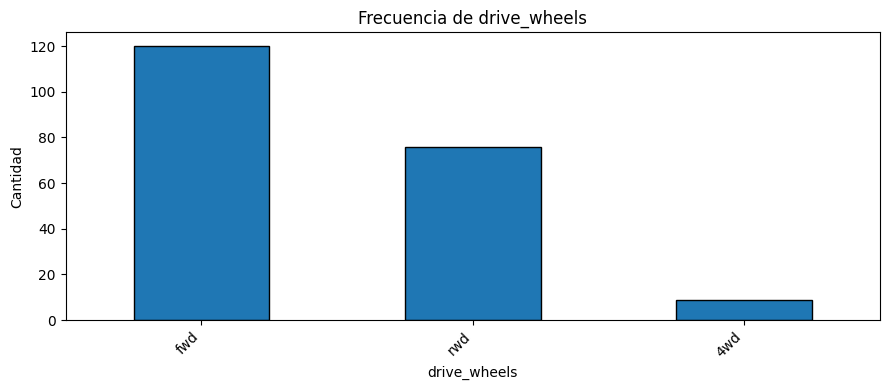

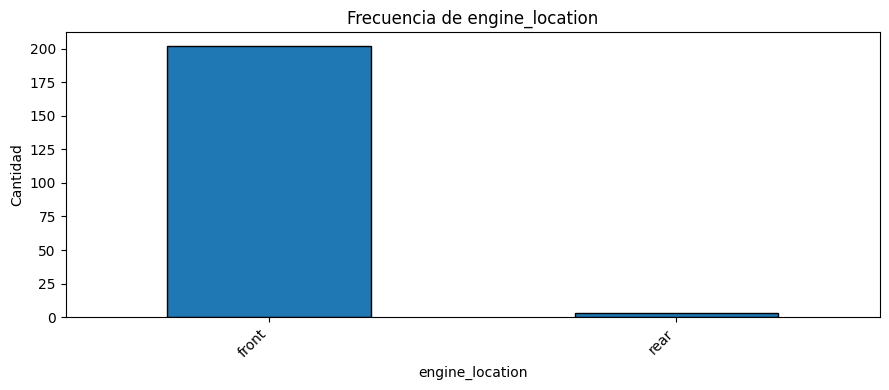

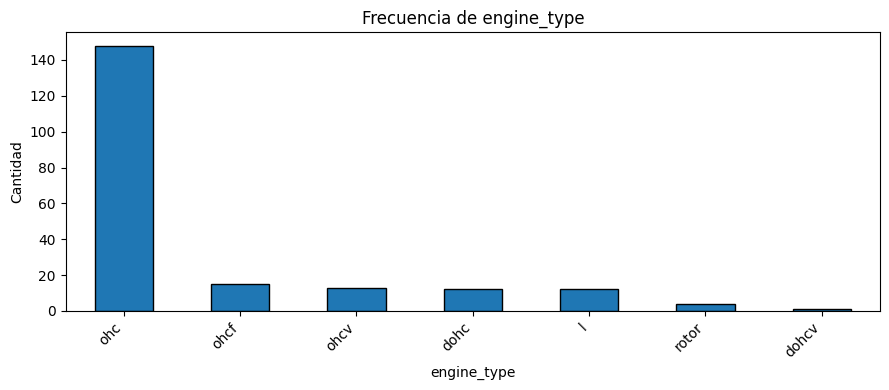

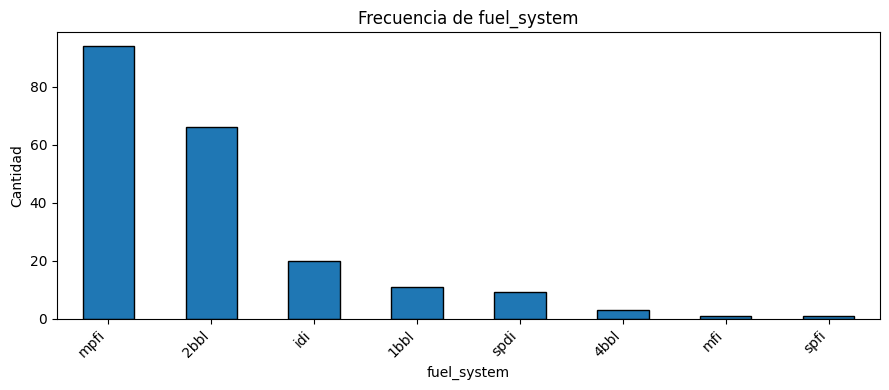

In [ ]:
print('Duplicados:', cars_df.duplicated().sum())

resumen_faltantes = pd.DataFrame({
    'Faltantes': cars_df.isna().sum(),
    'Porcentaje (%)': (
        cars_df.isna().mean() * 100
    ).round(2)
})

display(resumen_faltantes)

numericas_df = cars_df.select_dtypes(include=np.number)
categoricas_df = cars_df.select_dtypes(include='object')

estadisticas = numericas_df.describe().T
estadisticas['Asimetria'] = numericas_df.skew()
estadisticas['Curtosis'] = numericas_df.kurt()

display(estadisticas.round(2))

for columna in categoricas_df.columns:
    print('\n', columna)
    display(pd.DataFrame({
        'Frecuencia': categoricas_df[columna].value_counts(),
        'Porcentaje (%)': (
            categoricas_df[columna].value_counts(normalize=True) * 100
        ).round(2)
    }))

numericas_df.hist(
    bins=15, figsize=(18, 14), edgecolor='black'
)
plt.tight_layout()
plt.show()

for columna in categoricas_df.columns:
    plt.figure(figsize=(9, 4))
    categoricas_df[columna].value_counts().plot(
        kind='bar', edgecolor='black'
    )
    plt.title(f'Frecuencia de {columna}')
    plt.xlabel(columna)
    plt.ylabel('Cantidad')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

--------------
No se encontraron registros duplicados, normalized_losses tiene 41 valores faltantes (cerca 20% de los registros); bore y strok tienen 4 faltantes (cerca del 2%); horsepower y peak_rpm tienen 2 faltantes (cerca del 1%).
El precio promedio es aprox 13,150 dolares, la mediana es de 10,295 dolares. El precio maximo es de 45,400 y el minimo de 5,118. La asimetria positiva del precio es (1.84).
Predominan los automoviles de gasolina (185 vs 20 diesel), con aspiracion normal (168 frente a 37 turbo). Hay 96 sedanes y 70 hatchbacks. Toyota es la marca con mas registros (32), seguida de Nissan (18) y Mazda (17).
--------------

# Análisis exploratorio de datos (bivariado)

--------------
se creó una copia para la ingeniería de características, se sustituyó el año de lanzamiento por la antigüedad calculada y se discretizó la memoria de video en cuatro intervalos ordinales. El gráfico de barras permite evaluar cómo se distribuyen los dispositivos entre esos grupos.
--------------

3. Genera algunos gráficos bivariados para familiarizarte con el conjunto de datos:
* Gráfico de barras apiladas normalizadas que muestra la distribución de los tipos de tracción para cada fabricante.
* Diagrama de cajas para visualizar cómo se distribuye el precio de los automóviles según el estilo de carrocería. Esto permitirá comparar la mediana, los cuartiles y la presencia de valores atípicos entre los diferentes tipos de carrocería.
* Gráfico de barras que muestre los 10 automóviles más caros, ordenados de mayor a menor precio, con cada barra diferenciada con color por fabricante.
* Diagrama de dispersión para explorar la relación entre el tamaño del motor y el precio de los automóviles. Diferencia con colores los puntos según el tipo de aspiración y con el tamaño de los puntos el número de puertas.

**Nota.** Debes incluir en cada gráfico una conclusión de lo observado.

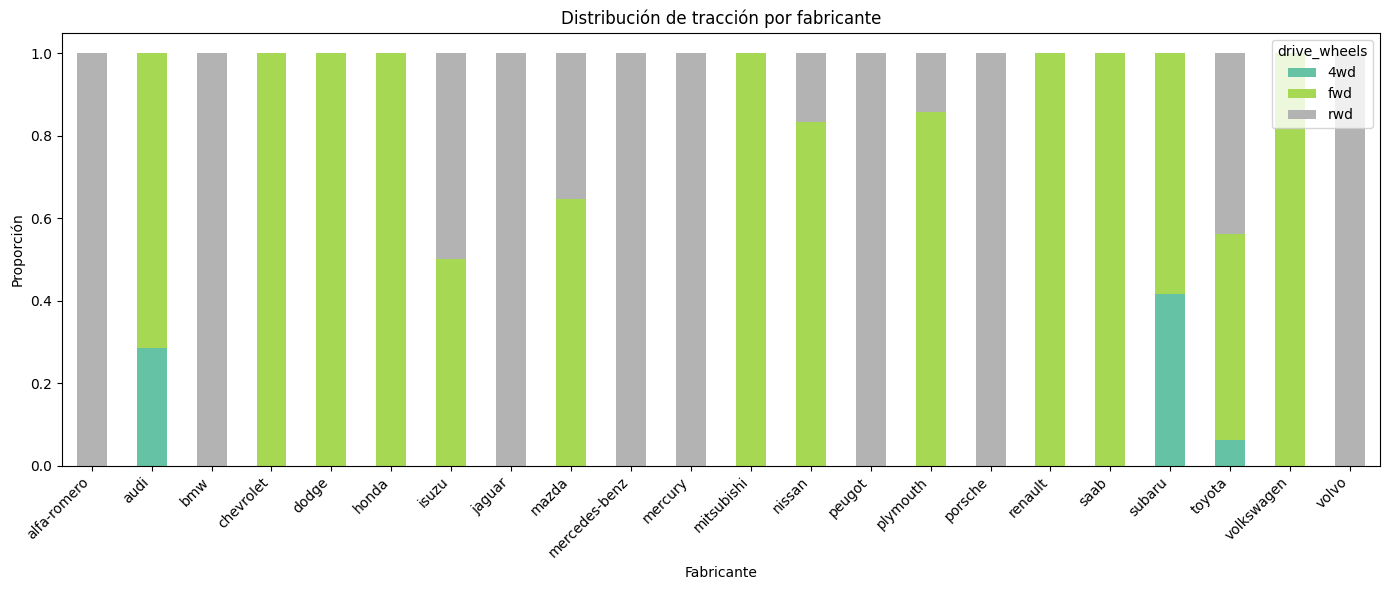

In [ ]:
pd.crosstab(
    cars_df['make'],
    cars_df['drive_wheels'],
    normalize='index'
).plot(
    kind='bar', stacked=True,
    figsize=(14, 6), colormap='Set2'
)

plt.title('Distribución de tracción por fabricante')
plt.xlabel('Fabricante')
plt.ylabel('Proporción')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

--------------
Alfa Romeo, BMW, Jaguar, Mercedes-Benz, Mercury, Peugeot y Porsche tienen registros exclusivamente de traccion trasera. Chevrolet, Dodge, Honda, Mitsubishi, Renault, Saab y Volkswagen presentan exclusivamente traccion delantera. Audi, Subaru y Toyota combinan distintos tipos de traccion
--------------

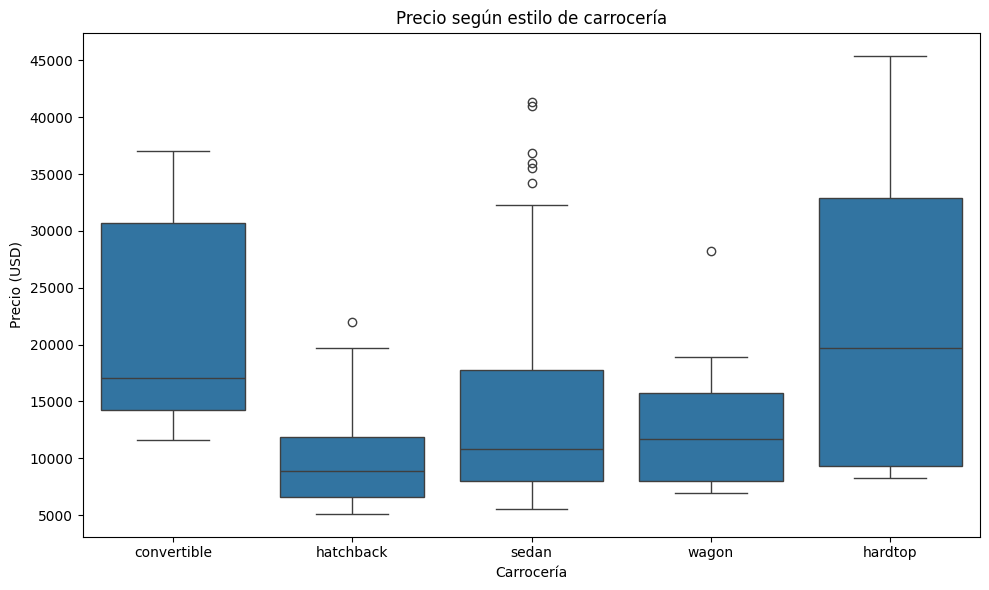

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=cars_df, x='body_style', y='price')
plt.title('Precio según estilo de carrocería')
plt.xlabel('Carrocería')
plt.ylabel('Precio (USD)')
plt.tight_layout()
plt.show()

--------------
Los hardtops tienen la mediana de precio mas elevada con 19,687.50 dolares y presenta el precio maximo del conjunto: 45,400, seguidos por los convertibles, con 17,084.50. Los hatchbacks tienen la mediana mas baja con 8,897.
--------------

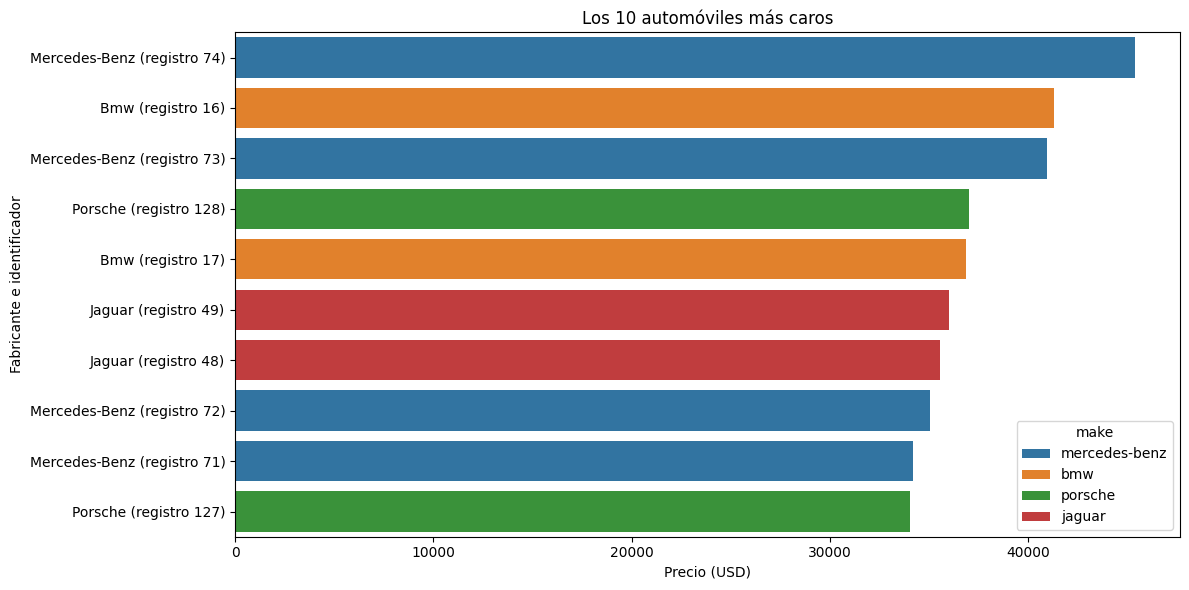

In [ ]:
top_10 = cars_df.nlargest(10, 'price').copy()

top_10['automovil'] = (
    top_10['make'].str.title()
    + ' (registro '
    + top_10.index.astype(str)
    + ')'
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_10, x='price', y='automovil',
    hue='make', dodge=False
)
plt.title('Los 10 automóviles más caros')
plt.xlabel('Precio (USD)')
plt.ylabel('Fabricante e identificador')
plt.tight_layout()
plt.show()

--------------
El coche mas caro es el Mercedes-Benz hardtop de 45,400 dolares. Le siguen un BMW de 41,315 y un Mercedes-Benz de 40,960. Mercedes-Benz aparece cuatro veces entre los diez registros mas caros; BMW, Jaguar y Porsche aparecen dos veces en el top 10.
--------------

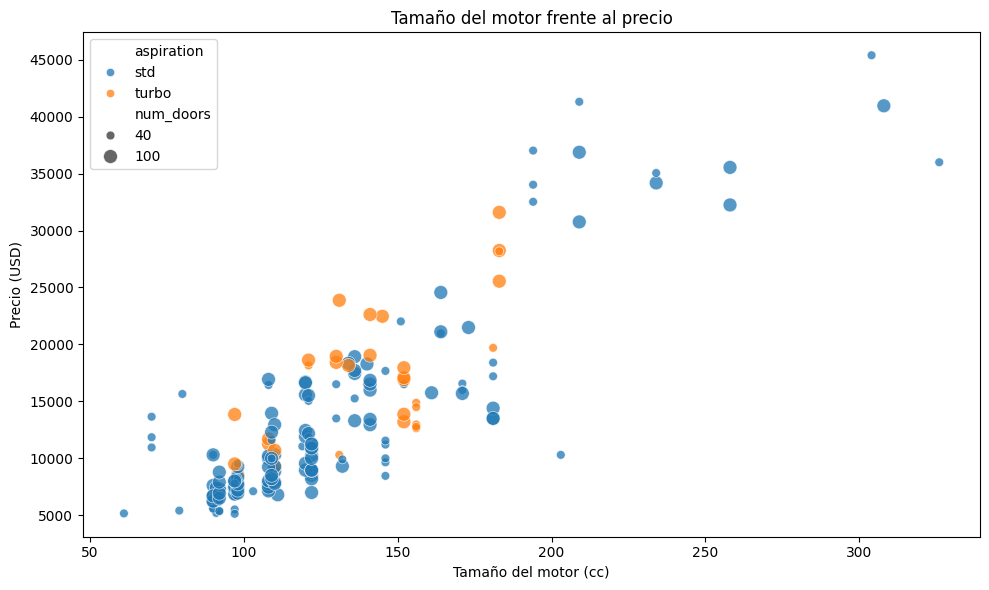

In [ ]:
tamanos_puntos = cars_df['num_doors'].map({
    'two': 40,
    'four': 100
})

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=cars_df,
    x='engine_size',
    y='price',
    hue='aspiration',
    size=tamanos_puntos,
    sizes=(40, 100),
    alpha=0.75
)

plt.title('Tamaño del motor frente al precio')
plt.xlabel('Tamaño del motor (cc)')
plt.ylabel('Precio (USD)')
plt.tight_layout()
plt.show()

--------------
Los motores mas grandes tienden a corresponder a autos mas caros. El grafico permite comparar las categorias de aspiracion normal y turbo, tambien distingue los autos de dos y cuatro puertas, pero la relacion entre tamaño del motor y precio es la tendencia principal.
--------------

4. Genera un mapa de calor de la matriz de correlación entre las variables numéricas del conjunto de datos, mostrando los valores de correlación en cada celda.
* ¿Cuáles son las tres variables más correlacionadas con el precio?

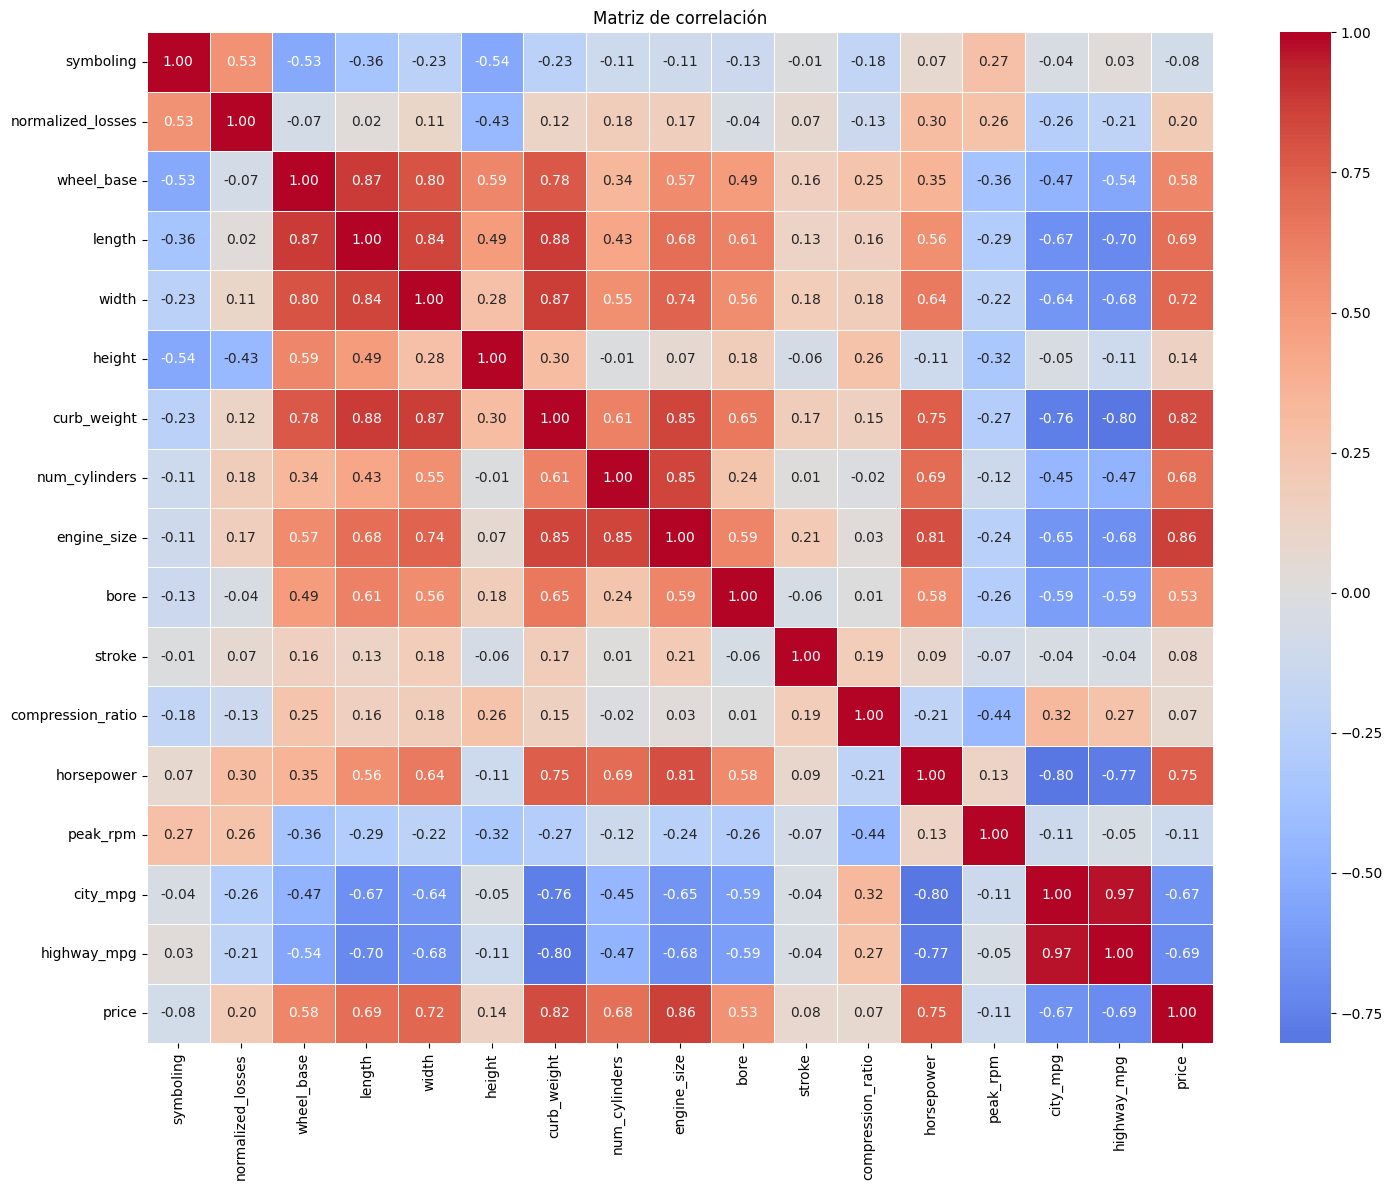

In [ ]:
matriz_correlacion = numericas_df.corr()

plt.figure(figsize=(15, 12))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

In [ ]:
correlacion_precio = (
    matriz_correlacion['price']
    .drop('price')
    .sort_values(key=abs, ascending=False)
)

display(correlacion_precio.head(3).to_frame(
    name='Correlación con price'
))

,Correlación con price
engine_size,0.860343
curb_weight,0.819817
horsepower,0.749844


--------------
La correlacion es positiva para las tres: los automoviles con motores mas grandes, mayor peso y mayor potencia tienden a presentar precios mas altos en este csv. La correlacion no demuestra causalidad y dificilmente podria funcionar como un modelo predictivo.
--------------

En el análisis de correlación se observa que existen muchos pares de variables altamente correlacionadas, lo que puede afectar el desempeño de los modelos de regresión. PCA resulta útil no solo para reducir la dimensionalidad, sino también porque los componentes principales son ortogonales entre sí, es decir, tienen correlación cero, evitando problemas de multicolinealidad. Esto lo podrás comprobrar más adelante.

# Ingeniería de características

5. Realiza las siguientes operaciones de ingeniería de características en las variables numéricas:
* Considera `price` como la variable objetivo y guárdala en `y`. Separa los predictores numéricos en `X`. Con base en estos datos, ¿cuántos componentes principales se generarán al aplicar PCA?
* Aplica `SimpleImputer` sobre `X` para tratar los valores faltantes, justificando la estrategia de imputación seleccionada.
* Realiza el escalamiento del conjunto `X` ya imputado, para que todas las variables contribuyan equitativamente y ninguna domine el análisis por tener una escala mayor.

In [ ]:
#Realiza las siguientes operaciones de ingeniería de características en las variables numéricas:
#Considera price como la variable objetivo y guárdala en y. Separa los predictores numéricos en X. Con base en estos datos, ¿cuántos componentes principales se generarán al aplicar PCA?
num_cols = cars_df.select_dtypes(include=['int64', 'float64']).columns.tolist()

y = cars_df['price']
X = cars_df[num_cols].drop(columns=['price'])

print('X:', X.shape)
print('y:', y.shape)

X: (205, 16)
y: (205,)


# **¿cuántos componentes principales se generarán al aplicar PCA?**

se generan 16 componentes cuando aplicamos PCA


1.symboling             9. engine_size
2.normalized_losses    10. bore
3.wheel_base           11. stroke
4.length               12. compression_ratio
5.width                13. horsepower
6.height               14. peak_rpm
7.curb_weight          15. city_mpg
8.num_cylinders        16. highway_mpg

In [ ]:
#Aplica SimpleImputer sobre X para tratar los valores faltantes, justificando la estrategia de imputación seleccionada.
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns, index=X.index)

print('Valores imputados:')
for col, val in zip(X.columns, imputer.statistics_):
    print(f'  {col:20s} -> {val}')

Valores imputados:
  symboling            -> 1.0
  normalized_losses    -> 115.0
  wheel_base           -> 97.0
  length               -> 173.2
  width                -> 65.5
  height               -> 54.1
  curb_weight          -> 2414.0
  num_cylinders        -> 4.0
  engine_size          -> 120.0
  bore                 -> 3.31
  stroke               -> 3.29
  compression_ratio    -> 9.0
  horsepower           -> 95.0
  peak_rpm             -> 5200.0
  city_mpg             -> 24.0
  highway_mpg          -> 30.0


JUSTIFICACION:


se eligió la media, debido a que en los apuntes de las semanas anteriores se especifica que cuando una distribución presenta asimetría o valores atípicos, la mediana es la métrica de tendencia central más robusta, en nuestro caso, la variable horsepaowerpresenta 6 outliers y la variable stroke presenta 20.
la media es una métrica muy sensible  a los valores atípicos y a la asimetría y es por eso que no se decide usarla.

In [ ]:
#Realiza el escalamiento del conjunto X ya imputado, para que todas las variables contribuyan equitativamente y ninguna domine el análisis por tener una escala mayor.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

print('Media después de estandarizar:', X_scaled.mean().round(4).unique())
print('Desv. estándar después:', X_scaled.std(ddof=0).round(4).unique())

Media después de estandarizar: [0.]
Desv. estándar después: [1.]


PCA está diseñado principalmente para variables numéricas y funciona encontrando combinaciones lineales de las variables originales que capturan la mayor varianza en los datos. Normalmente se recomienda eliminar las variables categóricas antes de aplicar PCA y luego concatenarlas nuevamente con los resultados de PCA si se desea.

6. Aplica `PCA` a los datos escalados para proyectarlos en el nuevo espacio de vectores.
* Asigna nombres descriptivos a los componentes principales en el dataframe resultante, utilizando la convención PC1, PC2, PC3, y así sucesivamente.
* Genera un mapa de calor con la matriz de correlaciones de los componentes principales para verificar que sean independientes entre sí.

In [ ]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

nombres = [f'PC{i+1}' for i in range(X_pca.shape[1])]
X_pca = pd.DataFrame(X_pca, columns=nombres, index=X_scaled.index)

X_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,1.370499,-1.130802,-1.013703,0.502983,0.657052,0.174955,-0.008520,0.118635,-0.111688
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,0.400032,0.293338,0.168137,0.039239,-0.022832,-0.078891,-0.391786,0.009265,0.053641
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,0.870186,0.015429,-0.447054,-0.055376,-0.416053,-0.049431,0.079357,-0.198402,0.046303


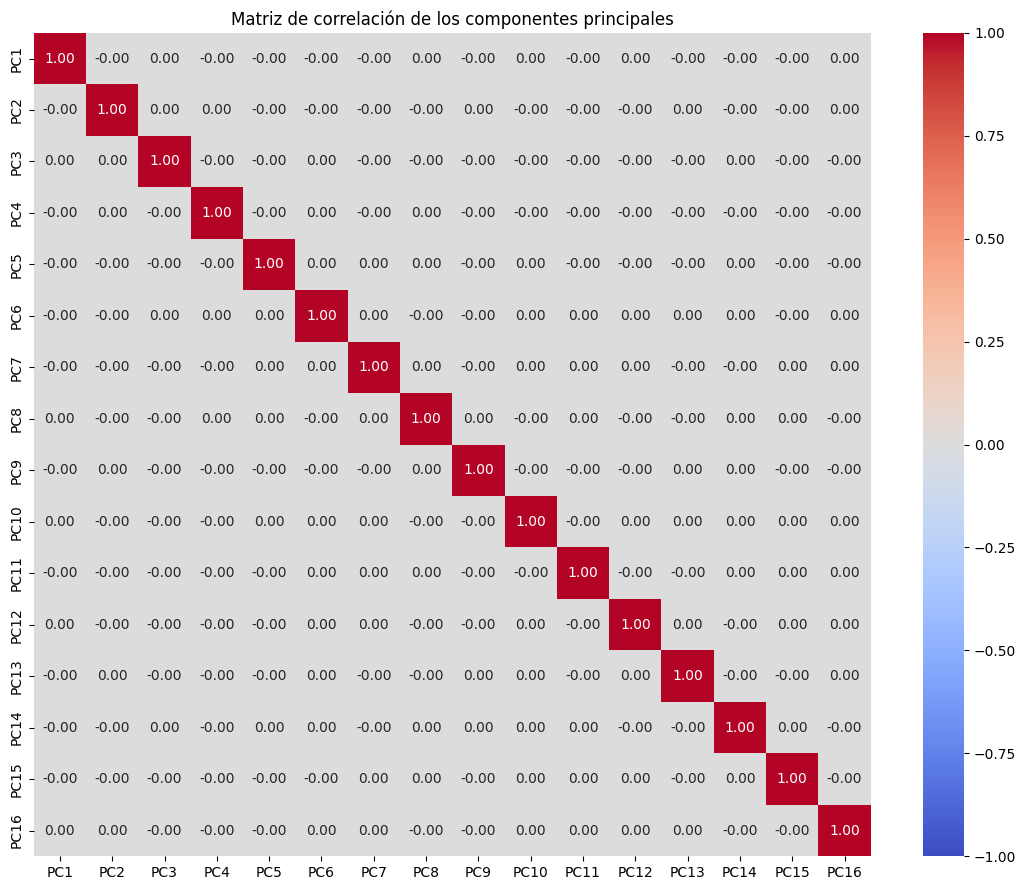

In [ ]:
#Genera un mapa de calor con la matriz de correlaciones de los componentes principales para verificar que sean independientes entre sí.
corr_pca = X_pca.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(round(corr_pca, 2), annot=True, cmap='coolwarm', center=0, fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de correlación de los componentes principales')
plt.tight_layout()
plt.show()

**en el mapa de calor vemos la diagonal roja de 1.00 y los valores por arriba y por abajo de este en ceros lo que nos indica la independencia entre sí**

7. Obtén el porcentaje de varianza explicada por cada componente.
* Grafica la curva de varianza acumulada para determinar el número mínimo de componentes principales que explican más del 90% de la varianza total.

,Componente,Varianza Explicada (%),Varianza Acumulada (%)
0,PC1,44.55,44.55
1,PC2,17.93,62.48
2,PC3,8.58,71.05
3,PC4,6.44,77.49
4,PC5,5.74,83.23
5,PC6,4.78,88.01
6,PC7,3.25,91.26
7,PC8,2.73,93.98
8,PC9,1.94,95.92
9,PC10,1.55,97.48


Númro mínimo de componentes para explicar >90% de la varianza: 7 (91.26%)


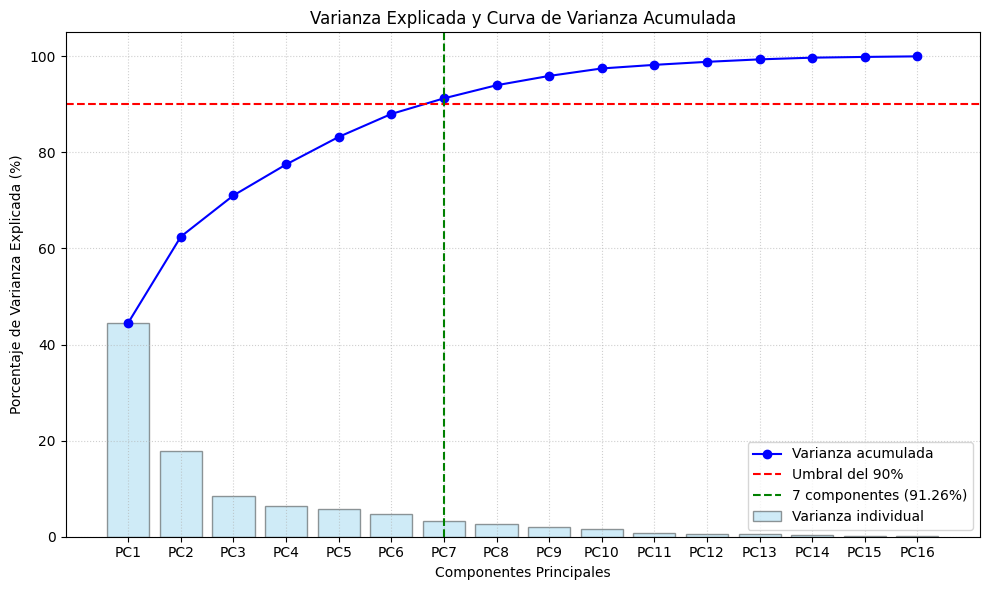

In [ ]:
varianza_explicada = pca.explained_variance_ratio_ * 100
varianza_acumulada = np.cumsum(varianza_explicada)

df_varianza = pd.DataFrame({
    'Componente': nombres,
    'Varianza Explicada (%)': varianza_explicada.round(2),
    'Varianza Acumulada (%)': varianza_acumulada.round(2)
})

display(df_varianza)


n_componentes_90 = np.argmax(varianza_acumulada >= 90) + 1
print(f"Númro mínimo de componentes para explicar >90% de la varianza: {n_componentes_90} ({varianza_acumulada[n_componentes_90-1]:.2f}%)")


plt.figure(figsize=(10, 6))
plt.bar(range(1, len(varianza_explicada) + 1), varianza_explicada, alpha=0.4, color='skyblue', edgecolor='black', label='Varianza individual')
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', linestyle='-', color='b', label='Varianza acumulada')
plt.axhline(y=90, color='r', linestyle='--', label='Umbral del 90%')
plt.axvline(x=n_componentes_90, color='g', linestyle='--', label=f'{n_componentes_90} componentes ({varianza_acumulada[n_componentes_90-1]:.2f}%)')

plt.xticks(range(1, len(nombres) + 1), nombres)
plt.xlabel('Componentes Principales')
plt.ylabel('Porcentaje de Varianza Explicada (%)')
plt.title('Varianza Explicada y Curva de Varianza Acumulada')
plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

8. Imprime la información de los componentes seleccionados (cargas o pesos de las variables originales) para interpretar qué variables contribuyen más a cada componente principal.
* Dibuja un diagrama de barras que muestre qué variables originales aportan más al primer componente principal (PC1), para visualizar su influencia relativa.

Cargas (pesos) de las variables originales en los 7 componentes seleccionados:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
symboling,-0.0974,-0.4028,0.2654,-0.0717,-0.3659,0.1735,0.1278
normalized_losses,0.0157,-0.3308,0.3083,-0.3431,-0.3761,-0.4921,-0.3226
wheel_base,0.2978,0.2646,-0.0295,-0.2283,-0.0044,-0.1835,-0.1063
length,0.3376,0.1387,-0.0439,-0.1941,-0.0735,-0.0822,-0.0087
width,0.3342,0.0552,0.1086,-0.0977,-0.0164,-0.1072,0.1399
height,0.1139,0.4217,-0.2825,-0.1861,-0.0167,-0.2140,-0.0026
curb_weight,0.3619,0.0224,0.0803,-0.0251,-0.0423,-0.0135,0.0612
num_cylinders,0.2452,-0.1141,0.1767,0.5521,0.2367,-0.3541,-0.0683
engine_size,0.3301,-0.0816,0.1989,0.2955,0.1088,0.0156,-0.0731
bore,0.2627,0.0031,-0.1382,0.0407,-0.3730,0.5119,0.1262


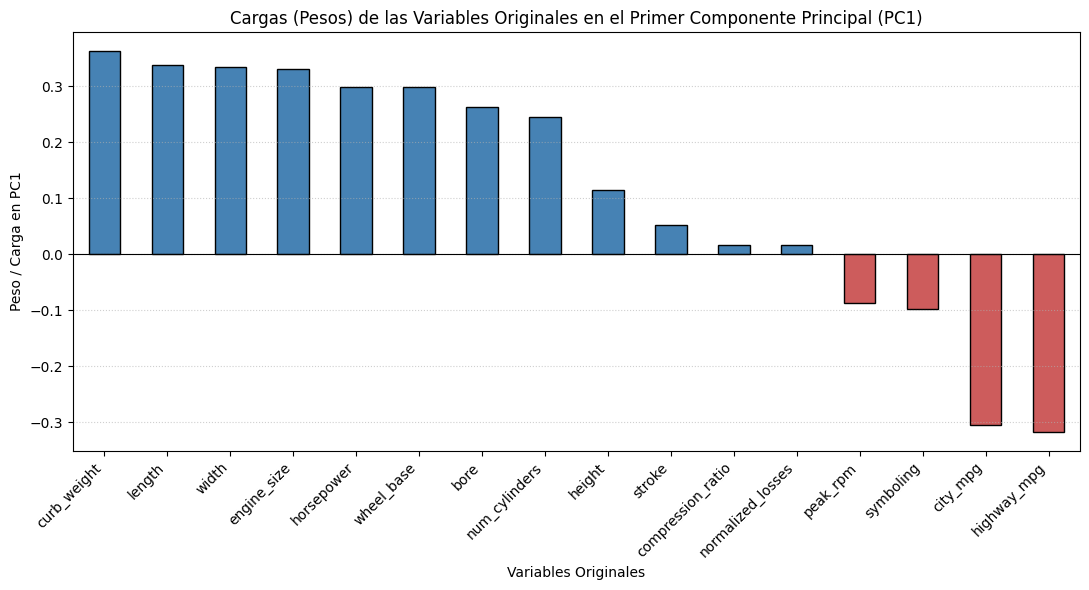

In [ ]:
cargas_df = pd.DataFrame(
    pca.components_[:n_componentes_90].T,
    columns=nombres[:n_componentes_90],
    index=X.columns
)

print("Cargas (pesos) de las variables originales en los 7 componentes seleccionados:")
display(cargas_df.round(4))


pc1_cargas = cargas_df['PC1'].sort_values(ascending=False)

plt.figure(figsize=(11, 6))
colores = ['steelblue' if v >= 0 else 'indianred' for v in pc1_cargas.values]
pc1_cargas.plot(kind='bar', color=colores, edgecolor='black')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Cargas (Pesos) de las Variables Originales en el Primer Componente Principal (PC1)')
plt.xlabel('Variables Originales')
plt.ylabel('Peso / Carga en PC1')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

9. Codifica las variables categóricas mediante *One-Hot Encoding* y utiliza el parámetro `drop='first'` para evitar problemas de multicolinealidad entre las variables dummy generadas.

In [ ]:
# Pregunta 9: One-Hot Encoding de las variables categóricas.
columnas_categoricas = cars_df.select_dtypes(include=['object', 'category']).columns.tolist()

# La imputación de la pregunta 5 se aplicó a las numéricas.
# Para poder codificar las categóricas, se completan sus faltantes con la moda.
categoricas = cars_df[columnas_categoricas].copy()
categoricas = categoricas.fillna(categoricas.mode().iloc[0])

encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
datos_ohe = encoder.fit_transform(categoricas)

ohe_df = pd.DataFrame(
    datos_ohe,
    columns=encoder.get_feature_names_out(columnas_categoricas),
    index=cars_df.index
)

print('Variables categóricas originales:', len(columnas_categoricas))
print('Columnas codificadas:', ohe_df.shape[1])
display(ohe_df.head())

Variables categóricas originales: 9
Columnas codificadas: 44


,make_audi,make_bmw,make_chevrolet,make_dodge,make_honda,make_isuzu,make_jaguar,make_mazda,make_mercedes-benz,make_mercury,...,engine_type_ohcf,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


**Conclusión de la pregunta 9.** Las variables categóricas se transforman en indicadores numéricos mediante One-Hot Encoding. El parámetro `drop='first'` elimina una categoría de referencia por variable para evitar redundancia entre las columnas dummy. Los valores faltantes categóricos, si existen, se imputan con la categoría más frecuente antes de codificar.

10. Conjunta, en un dataframe, las valores proyectados en los componentes seleccionados (mínimo), las transformaciones obtenidas de las variables categóricas y la variable de salida.
* Almacena el dataframe resultante en archivo.

In [ ]:
# Pregunta 10: Integración de los componentes principales seleccionados,
# las variables categóricas codificadas y el precio original.
componentes_seleccionados = X_pca.iloc[:, :n_componentes_90].copy()

cars_final_df = pd.concat(
    [componentes_seleccionados, ohe_df, y.rename('price')],
    axis=1
)

print('Dimensiones del conjunto final:', cars_final_df.shape)
print('Valores faltantes:', int(cars_final_df.isna().sum().sum()))
display(cars_final_df.head())

archivo_salida = 'automobile_pca_final_equipo.csv'
cars_final_df.to_csv(archivo_salida, index=False)
print('Archivo generado:', archivo_salida)

Dimensiones del conjunto final: (205, 52)
Valores faltantes: 0


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,make_audi,make_bmw,make_chevrolet,...,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi,price
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13495
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13950
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,17450


Archivo generado: automobile_pca_final_equipo.csv


**Conclusión de la pregunta 10.** El conjunto final reúne únicamente los componentes principales necesarios para explicar al menos el 90 % de la varianza de los predictores numéricos, las variables categóricas codificadas y el precio original como variable objetivo. Se conserva el índice para alinear correctamente los registros y se exporta un CSV sin columna de índice adicional.